In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
df_full_train = pd.read_csv("/workspaces/seeking-job-change-prediction/data/raw/aug_train.csv")
df_test = pd.read_csv("/workspaces/seeking-job-change-prediction/data/raw/aug_test.csv")
df_full_train.sample(5)

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
681,6010,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,8,10000+,Pvt Ltd,2,44,0.0
16576,17802,city_21,0.624,Male,Has relevent experience,no_enrollment,Masters,STEM,9,10000+,Pvt Ltd,>4,6,1.0
8647,23263,city_103,0.920,NaN,No relevent experience,Full time course,Graduate,STEM,4,NaN,NaN,never,22,1.0
8291,2541,city_75,0.939,Male,No relevent experience,no_enrollment,Primary School,NaN,3,NaN,NaN,never,68,0.0
17043,8656,city_150,0.698,Male,Has relevent experience,no_enrollment,High School,NaN,4,<10,Pvt Ltd,1,34,1.0


In [3]:
df_full_train.shape

(19158, 14)

In [4]:
df_full_train.dtypes

enrollee_id                 int64
city                          str
city_development_index    float64
gender                        str
relevent_experience           str
enrolled_university           str
education_level               str
major_discipline              str
experience                    str
company_size                  str
company_type                  str
last_new_job                  str
training_hours              int64
target                    float64
dtype: object

In [5]:
df_full_train.isna().sum()

enrollee_id                  0
city                         0
city_development_index       0
gender                    4508
relevent_experience          0
enrolled_university        386
education_level            460
major_discipline          2813
experience                  65
company_size              5938
company_type              6140
last_new_job               423
training_hours               0
target                       0
dtype: int64

In [6]:
df_test.isna().sum()

enrollee_id                 0
city                        0
city_development_index      0
gender                    508
relevent_experience         0
enrolled_university        31
education_level            52
major_discipline          312
experience                  5
company_size              622
company_type              634
last_new_job               40
training_hours              0
dtype: int64

In [7]:
for col in df_full_train.columns:
    print(col)
    print(df_full_train[col].unique()[:10])  # First 5 unique values
    print(df_full_train[col].nunique(),"\n")

enrollee_id
[ 8949 29725 11561 33241   666 21651 28806   402 27107   699]
19158 

city
<StringArray>
['city_103',  'city_40',  'city_21', 'city_115', 'city_162', 'city_176',
 'city_160',  'city_46',  'city_61', 'city_114']
Length: 10, dtype: str
123 

city_development_index
[0.92  0.776 0.624 0.789 0.767 0.764 0.762 0.913 0.926 0.827]
93 

gender
<StringArray>
['Male', nan, 'Female', 'Other']
Length: 4, dtype: str
3 

relevent_experience
<StringArray>
['Has relevent experience', 'No relevent experience']
Length: 2, dtype: str
2 

enrolled_university
<StringArray>
['no_enrollment', 'Full time course', nan, 'Part time course']
Length: 4, dtype: str
3 

education_level
<StringArray>
['Graduate', 'Masters', 'High School', nan, 'Phd', 'Primary School']
Length: 6, dtype: str
5 

major_discipline
<StringArray>
['STEM', 'Business Degree', nan, 'Arts', 'Humanities', 'No Major', 'Other']
Length: 7, dtype: str
6 

experience
<StringArray>
['>20', '15', '5', '<1', '11', '13', '7', '17', '2', '16']

In [8]:
df_full_train = df_full_train.drop(columns = ['enrollee_id'])

In [9]:
df_full_train.target = (df_full_train.target == 1.0).astype(bool)

In [10]:
df_full_train.relevent_experience = (df_full_train.relevent_experience == 'Has relevent experience').astype(bool)
df_test.relevent_experience = (df_test.relevent_experience == 'Has relevent experience').astype(bool)

In [11]:
strings = list(df_full_train.dtypes[df_full_train.dtypes == 'str'].index)
for col in strings:
    df_full_train[col] = df_full_train[col].str.lower().str.replace(' ', '_')
    df_test[col] = df_test[col].str.lower().str.replace(' ', '_')

In [12]:
df_test.gender.value_counts(dropna=False)

gender
male      1460
NaN        508
female     137
other       24
Name: count, dtype: int64

In [13]:
for col in ['gender','enrolled_university','enrolled_university','education_level','major_discipline','company_type']:
    df_full_train[col] = df_full_train[col].fillna("NA")
    df_test[col] = df_test[col].fillna("NA")

In [14]:
df_full_train.experience.value_counts(dropna=False)

experience
>20    3286
5      1430
4      1403
3      1354
6      1216
2      1127
7      1028
10      985
9       980
8       802
15      686
11      664
14      586
1       549
<1      522
16      508
12      494
13      399
17      342
19      304
18      280
20      148
NaN      65
Name: count, dtype: int64

In [15]:
experience_values = {'>20':21,'<1':0}
df_full_train.experience = df_full_train.experience.replace(experience_values).fillna(-1).astype('int')
df_test.experience = df_test.experience.replace(experience_values).fillna(-1).astype('int')

In [16]:
df_full_train.company_size.value_counts(dropna=False)

company_size
NaN          5938
50-99        3083
100-500      2571
10000+       2019
10/49        1471
1000-4999    1328
<10          1308
500-999       877
5000-9999     563
Name: count, dtype: int64

In [17]:
company_size_values = {'<10':0,'10/49':1,'50-99':2,'100-500':3,'500-999':4,'1000-4999':5,'5000-9999':6,'10000+':7}
df_full_train.company_size = df_full_train.company_size.replace(company_size_values).fillna(-1).astype('int')
df_test.company_size = df_test.company_size.replace(company_size_values).fillna(-1).astype('int')

In [18]:
df_full_train.last_new_job.value_counts(dropna=False)

last_new_job
1        8040
>4       3290
2        2900
never    2452
4        1029
3        1024
NaN       423
Name: count, dtype: int64

In [19]:
last_new_job_values = {'never':0,'1':1,'2':2,'3':3,'4':4,'>4':5}
df_full_train.last_new_job = df_full_train.last_new_job.replace(last_new_job_values).fillna(-1).astype('int')
df_test.last_new_job = df_test.last_new_job.replace(last_new_job_values).fillna(-1).astype('int')

In [20]:
df_full_train.describe().round()

,city_development_index,experience,company_size,last_new_job,training_hours
count,19158.0,19158.0,19158.0,19158.0,19158.0
mean,1.0,10.0,2.0,2.0,65.0
std,0.0,7.0,3.0,2.0,60.0
min,0.0,-1.0,-1.0,-1.0,1.0
25%,1.0,4.0,-1.0,1.0,23.0
50%,1.0,9.0,2.0,1.0,47.0
75%,1.0,16.0,3.0,3.0,88.0
max,1.0,21.0,7.0,5.0,336.0


In [21]:
numerical = ['city_development_index','experience','company_size','training_hours']
categorical = ['city','gender','relevent_experience','enrolled_university','education_level','major_discipline','company_type','last_new_job']

In [22]:
df_full_train.sample(20)

,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
18574,city_105,0.794,male,True,no_enrollment,graduate,stem,11,7,pvt_ltd,2,17,False
3751,city_73,0.754,male,True,no_enrollment,masters,humanities,21,-1,NA,2,26,False
8770,city_103,0.920,male,True,no_enrollment,masters,stem,21,-1,NA,5,6,True
241,city_103,0.920,male,False,full_time_course,high_school,NA,3,7,pvt_ltd,1,30,False
8521,city_102,0.804,female,True,no_enrollment,masters,stem,21,3,pvt_ltd,3,92,False
493,city_103,0.920,NA,False,no_enrollment,graduate,stem,4,7,public_sector,1,5,False
12142,city_103,0.920,male,False,no_enrollment,masters,stem,19,0,early_stage_startup,2,24,False
1565,city_16,0.910,male,True,no_enrollment,masters,stem,21,5,public_sector,5,3,False
3499,city_74,0.579,NA,True,no_enrollment,graduate,stem,7,3,pvt_ltd,1,9,False
8172,city_136,0.897,male,True,no_enrollment,masters,stem,19,1,pvt_ltd,1,16,True


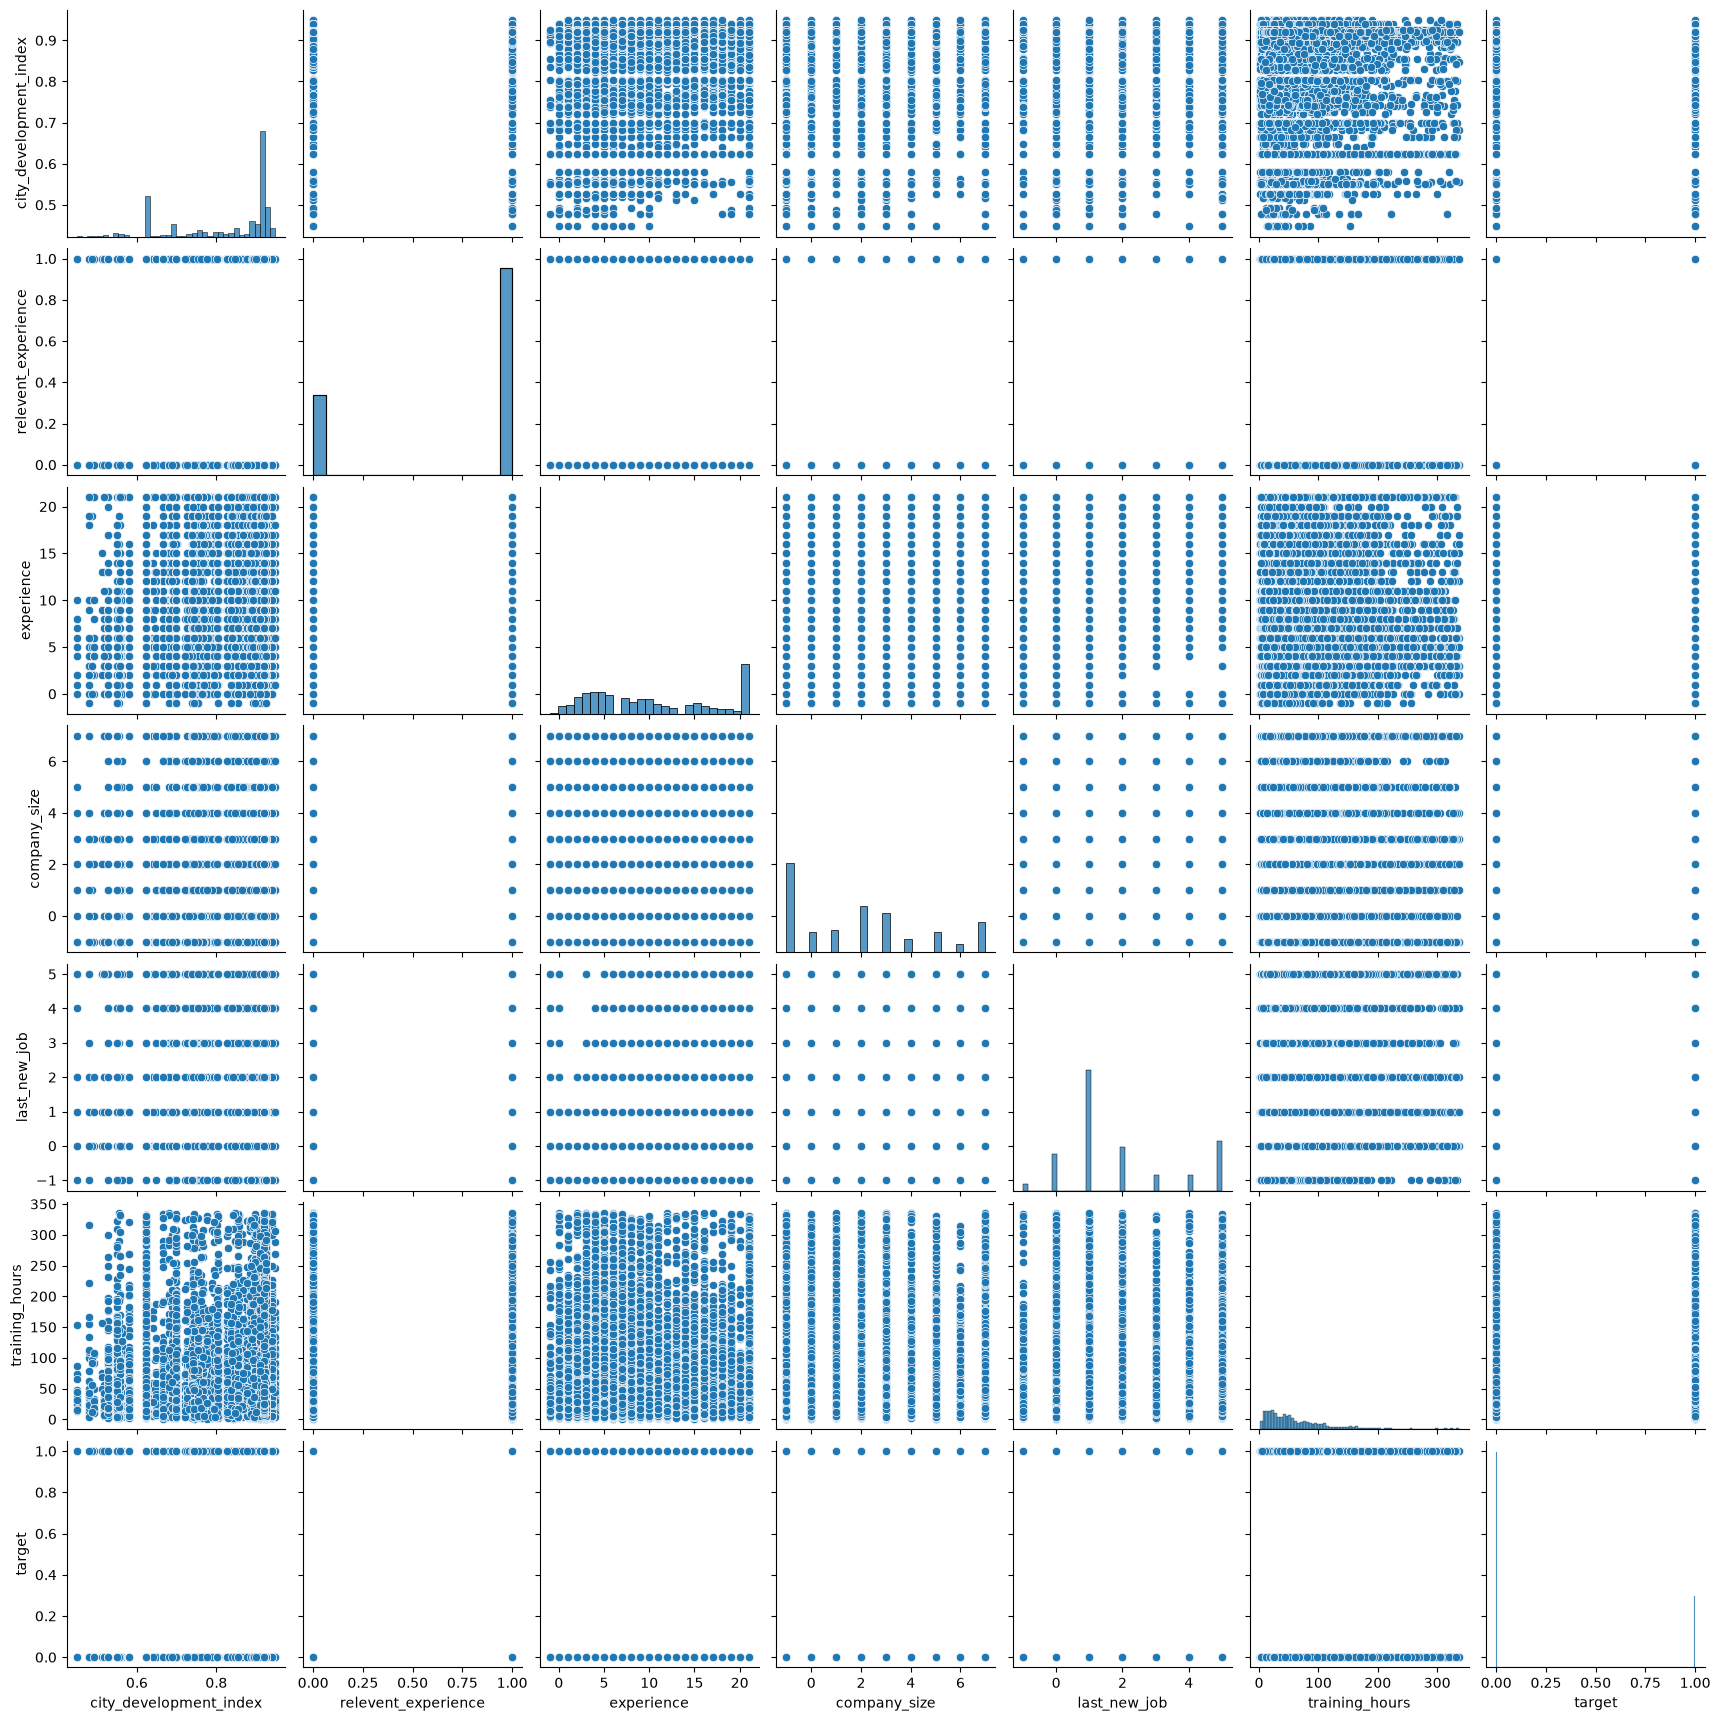

In [23]:
sns.pairplot(df_full_train)

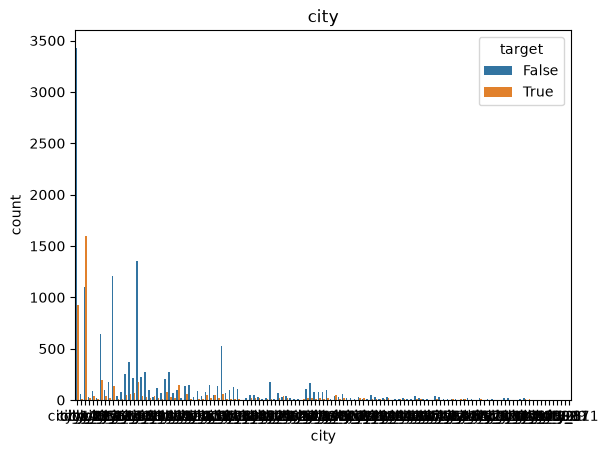

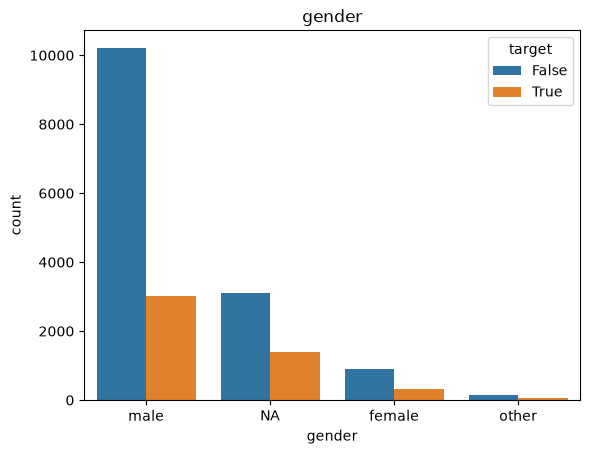

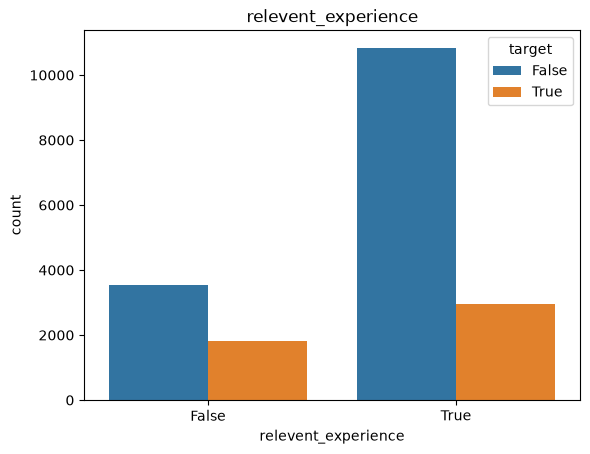

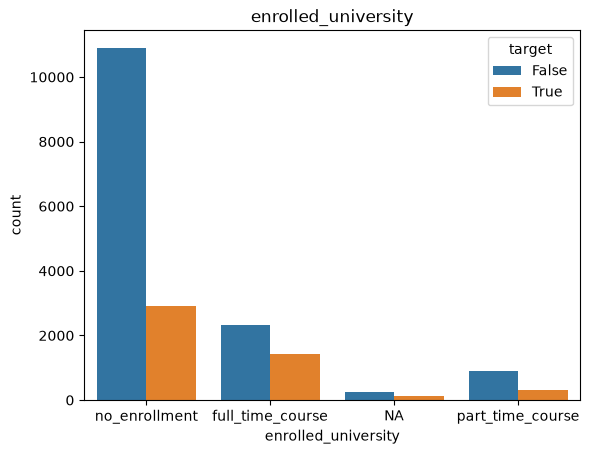

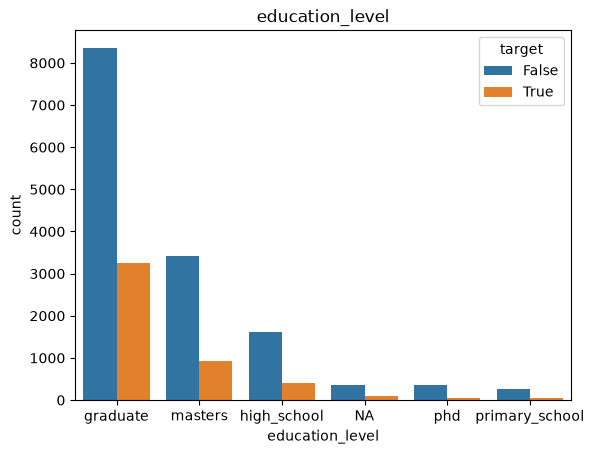

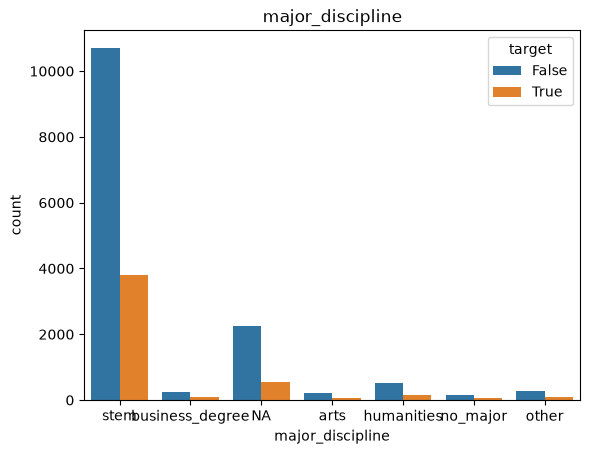

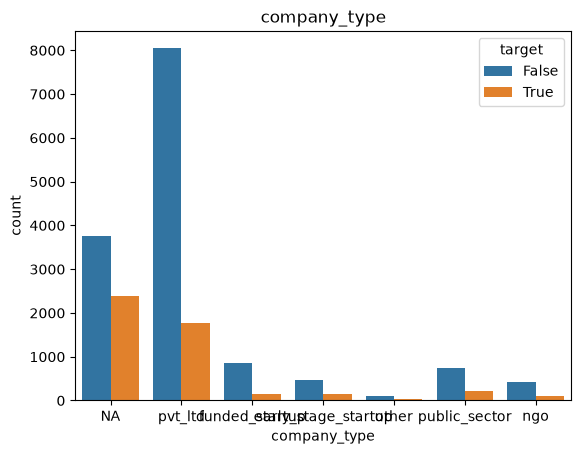

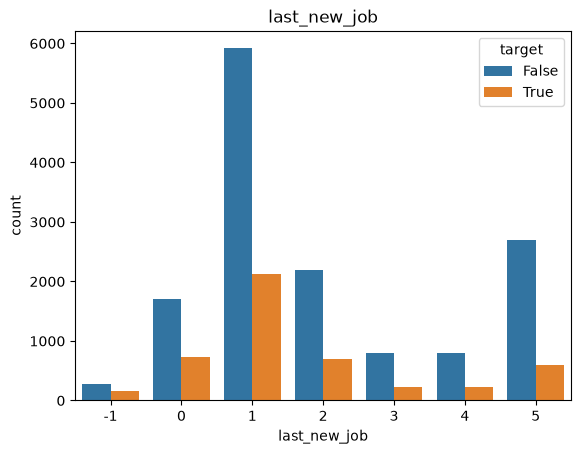

In [24]:
for col in categorical:
    sns.countplot(data=df_full_train, x=col, hue='target')
    plt.title(col)
    plt.show()

In [25]:
from sklearn.model_selection import train_test_split

In [26]:
df_train, df_val = train_test_split(df_full_train, test_size = 0.2, random_state = 42, stratify = df_full_train.target)

In [27]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [28]:
y_train = df_train.target.values
y_val = df_val.target.values

del df_train['target']
del df_val['target']

In [29]:
df_train.to_csv('data/processed/train.csv')
df_val.to_csv('data/processed/val.csv')
df_test.to_csv('data/processed/test.csv')

pd.Series(y_train).to_csv('data/processed/y_train.csv', index=False)
pd.Series(y_val).to_csv('data/processed/y_val.csv', index=False)